<center><image src="https://drive.google.com/uc?id=1n3G4TdK_u6PQHcLrxB_A0HijNdigXmUH">

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Сегментация изображений</b></h3>


В этом задании вам предстоит решить задачу сегментации медицинских снимков. Домашнее задание можно разделить на следующие части:

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]
* Мир других лоссов! [2]
  * Dice Loss [1]
  * Focal Loss [1]
  * BONUS: лосс из статьи [5]
* Новая модель! [2]
  * UNet [2]


**Максимальный балл:** 10 баллов.

Также для студентов желающих еще более углубиться в задачу предлагается решить бонусное задание, которое даст дополнительные 5 баллов. BONUS задание необязательное.


# Шаг 1. Загрузка и подготовка данных

1. Для начала мы скачаем датасет: [ADDI project](https://www.fc.up.pt/addi/ph2%20database.html).

<table><tr><td>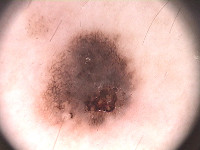</td><td>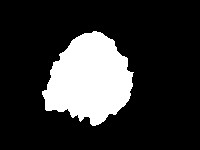</td></tr></table>

2. Разархивируем .rar файл.
3. Обратите внимание, что папка  `PH2 Dataset images` должна лежать там же где и ipynb notebook.

Это фотографии двух типов **поражений кожи:** меланома и родинки.
В данном задании мы не будем заниматься их классификацией, а будем **сегментировать** их.

In [1]:
!gdown 1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql

Downloading...
From (original): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql
From (redirected): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql&confirm=t&uuid=c523b0c8-a049-4219-a381-67b4211c93e8
To: /content/PH2Dataset.rar
100% 162M/162M [00:01<00:00, 155MB/s]


In [2]:
get_ipython().system_raw("unrar x PH2Dataset.rar")

Стуктура датасета у нас следующая:

    IMD_002/
        IMD002_Dermoscopic_Image/
            IMD002.bmp
        IMD002_lesion/
            IMD002_lesion.bmp
        IMD002_roi/
            ...
    IMD_003/
        ...
        ...

 Здесь `X.bmp` — изображение, которое нужно сегментировать, `X_lesion.bmp` — результат сегментации.

Для загрузки датасета можно использовать skimage: [`skimage.io.imread()`](https://scikit-image.org/docs/dev/api/skimage.io.html)

In [3]:
images = []
lesions = []
from skimage.io import imread
import os
root = 'PH2Dataset'

for root, dirs, files in os.walk(os.path.join(root, 'PH2 Dataset images')):
    if root.endswith('_Dermoscopic_Image'):
        images.append(imread(os.path.join(root, files[0])))
    if root.endswith('_lesion'):
        lesions.append(imread(os.path.join(root, files[0])))

Изображения имеют разные размеры. Давайте изменим их размер на $256\times256 $ пикселей. Для изменения размера изображений можно использовать [`skimage.transform.resize()`](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize).
Эта функция также автоматически нормализует изображения в диапазоне $[0,1]$.


In [4]:
from skimage.transform import resize
size = (256, 256)
X = [resize(x, size, mode='constant', anti_aliasing=True,) for x in images]
Y = [resize(y, size, mode='constant', anti_aliasing=False) > 0.5 for y in lesions]

In [5]:
import numpy as np
X = np.array(X, np.float32)
Y = np.array(Y, np.float32)
print(f'Loaded {len(X)} images')

Loaded 200 images


Чтобы убедиться, что все корректно, мы нарисуем несколько изображений

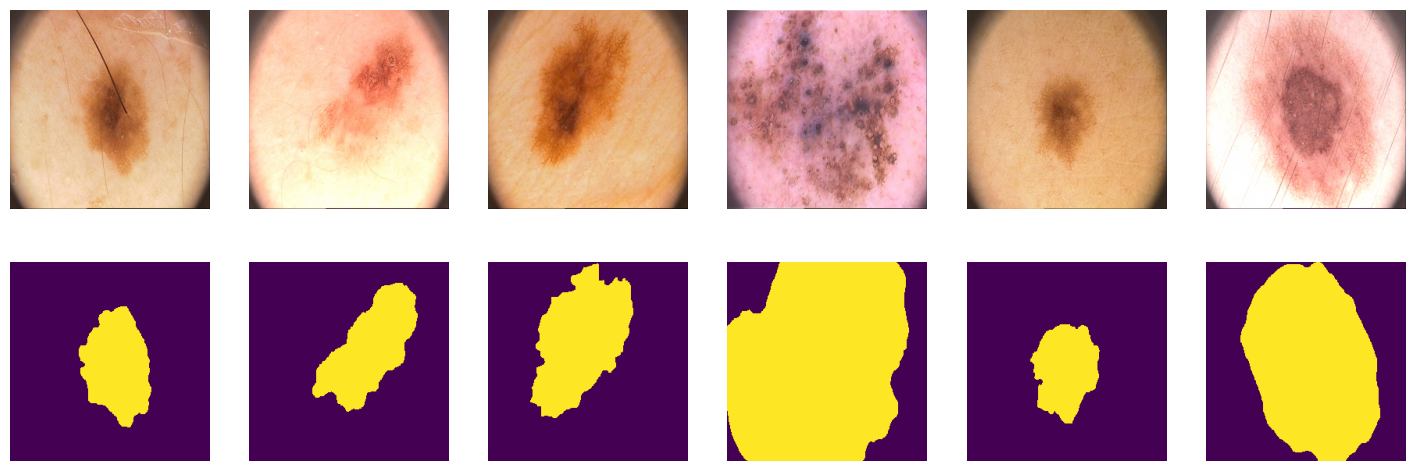

In [6]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.figure(figsize=(18, 6))
for i in range(6):
    plt.subplot(2, 6, i+1)
    plt.axis("off")
    plt.imshow(X[i])

    plt.subplot(2, 6, i+7)
    plt.axis("off")
    plt.imshow(Y[i])
plt.show();

Разделим наши 200 картинок на 100/50/50
 для обучения, валидации и теста соответственно

In [7]:
ix = np.random.choice(len(X), len(X), False)
tr, val, ts = np.split(ix, [100, 150])

In [8]:
print(len(tr), len(val), len(ts))

100 50 50


## PyTorch DataLoader

In [9]:
from torch.utils.data import DataLoader
batch_size = 25
train_dataloader = DataLoader(list(zip(np.rollaxis(X[tr], 3, 1), Y[tr, np.newaxis])),
                     batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(list(zip(np.rollaxis(X[val], 3, 1), Y[val, np.newaxis])),
                      batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(list(zip(np.rollaxis(X[ts], 3, 1), Y[ts, np.newaxis])),
                     batch_size=batch_size, shuffle=False)

In [10]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Шаг 2. Метрика качества модели

## IoU (intersection over union)

В данном разделе предлагается использовать следующую метрику для оценки качества:

$I o U=\frac{\text {target } \cap \text { prediction }}{\text {target } \cup{prediction }}$

Пересечение (A ∩ B) состоит из пикселей, найденных как в маске предсказания, так и в основной маске истины, тогда как объединение (A ∪ B) просто состоит из всех пикселей, найденных либо в маске предсказания, либо в целевой маске.


Что будет являться пересением и объединением в задаче сегментации?

Давайте разберем следующий пример:





<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1rBYFgli48AUUN9idiyq8j3J5DboB93yN" width=1000 height=800/></p>

In [11]:
!pip install torchmetrics

In [12]:
from torchmetrics import JaccardIndex

iou_score = JaccardIndex(threshold=0.5, task="binary", average='none').to(device)

# Задания: Построй свой первый бейзлайн!

Итак, загрузка файлов, код датасета и даталоадера написана за вас. Метрика IoU написана за вас! Вам остается написать лосс, модель и функции обучения и теста модели.

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]

## Шаг 3. Loss функция - BCE [2 балла]

Популярным лоссом для бинарной сегментации является *бинарная кросс-энтропия*, которая задается следующим образом:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

где $y$ это  таргет желаемого результата и $\hat y$ является выходом модели. $\sigma$ - это [*логистическая* функция](https://en.wikipedia.org/wiki/Sigmoid_function), который преобразует действительное число $\mathbb R$ в вероятность $[0,1]$.

Однако эта потеря страдает от проблем численной нестабильности. Самое главное, что $\lim_{x\rightarrow 0^+}\log(x)=-\infty$ приводит к неустойчивости в процессе оптимизации. Рекомендуется посмотреть следующее [упрощение](https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits). Эта функция эквивалентна первой и не так подвержена численной неустойчивости:

$$\mathcal L_{BCE} = \hat y^T \mathbf{1} - y^T \hat y + \mathbf{1}^T \log\left(1+\exp(-\hat y)\right) \space [2]$$

### Вывод численно стабильной формулы BCE лосса [1 балл]



Выведите из формулы [1] формулу [2]:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

Не забываем, что здесь $\hat y_i$ - это логиты сети, не вероятности и не лейблы.


### Ответ

Начальная формула для одного элемента:

$$
L = -[y\log(\sigma(\hat y))+(1-y)\log(1-\sigma(\hat y))]
$$

По определению сигмоиды:

$$
\sigma(\hat y)=\frac{1}{1+e^{-\hat y}}
$$

Следовательно:

$$
\log(\sigma(\hat y))=-\log(1+e^{-\hat y})
$$

$$
\log(1-\sigma(\hat y))=-\hat y-\log(1+e^{-\hat y})
$$

Подставляем в исходную формулу:

$$
L=y\log(1+e^{-\hat y})+(1-y)(\hat y+\log(1+e^{-\hat y}))
$$

Раскрываем скобки:

$$
L=y\log(1+e^{-\hat y})+\hat y-y\hat y+(1-y)\log(1+e^{-\hat y})
$$

Объединяем логарифмы:

$$
L=(y+1-y)\log(1+e^{-\hat y})+\hat y-y\hat y
$$

Получаем формулу [2]:

$$
\boxed{L=\hat y-y\hat y+\log(1+\exp(-\hat y))}
$$


### Реализуйте в коде оба варианта лосса [1 балл]

Реализуйте следующие функции:

*   `bce_true()` - честная прямая реализация лосса с формулой $$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$
*   `bce_loss()` - реализация формулы, которую мы вывели $$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right).$$

И сравните результаты функций с реализацией Pytorch:
*   `bce_torch()`
*   `bce_torch_with_logits()`

In [13]:
import torch.nn.functional as F
import torch.nn as nn

In [14]:
bce_torch = nn.BCELoss(reduction='sum') # (sigmoid(y_pred), y_real)
bce_torch_with_logits = nn.BCEWithLogitsLoss(reduction='sum')

In [15]:
# Формула 2
def bce_loss(y_pred, y_real):
    return torch.sum(
        y_pred - y_real * y_pred + torch.log(1 + torch.exp(-y_pred))
    )

# Формула 1
def bce_true(y_pred, y_real):
    y_pred = torch.sigmoid(y_pred)

    return -torch.sum(
        y_real * torch.log(y_pred)
        + (1 - y_real) * torch.log(1 - y_pred)
    )


Проверим корректность работы на простом примере

In [16]:
y_pred = torch.randn(3, 2, requires_grad=False)
y_true = torch.rand(3, 2, requires_grad=False)

print(f'BCE loss from scratch bce_loss             = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный                = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch              = {bce_torch(torch.sigmoid(y_pred), y_true)}')
print(f'BCE loss from torch with logits bce_torch  = {bce_torch_with_logits(y_pred, y_true)}')


BCE loss from scratch bce_loss             = 5.2098846435546875
BCE loss честно посчитанный                = 5.2098846435546875
BCE loss from torch bce_torch              = 5.2098846435546875
BCE loss from torch with logits bce_torch  = 5.2098846435546875


Инструкции `assert` в Python — это булевы выражения, которые проверяют, является ли условие истинным (`True`). Внизу в коде мы проверяем функция `bce_loss()` выдает тот же результат, что и функция из Pytorch или нет. Если равенства не будет, что будет означать, что результаты функций не совпадают, а значит вы неправильно реализовали фукнцию `bce_loss()`, `assert` возвратит ошибку.

Функция `numpy.isclose()` используется для сравнения двух чисел с учётом допустимой погрешности. Она особенно полезна при работе с числами с плавающей точкой, где точное сравнение может быть проблематичным из-за ограничений представления таких чисел в компьютере.

Как она работает?

`numpy.isclose(a, b, rtol=1e-05, atol=1e-08) `принимает два числа (`a` и `b`) и сравнивает их, учитывая относительную и абсолютную погрешность. Если разница между двумя числами меньше заданного порога, функция возвращает `True`, иначе — `False`.

Параметры:

    rtol: Относительная погрешность (по умолчанию 1e-05). Используется для определения разницы относительно большего значения.
    atol: Абсолютная погрешность (по умолчанию 1e-08). Определяет минимальную разницу, которую следует учитывать.

Мы будем использовать `assert` и `numpy.isclose()` для проверки корректности нашего кода.

In [17]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))

Давайте теперь посчитаем на простом примере, но с теми же размерностями, что и в датасете

In [18]:
y_pred = torch.randn((2, 1, 3, 3), requires_grad=False)
y_true = torch.randint(0, 2, (2, 1, 3, 3))

print(f'BCE loss from scratch bce_loss            = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный               = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch             = {bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float))}')
print(f'BCE loss from torch with logits bce_torch = {bce_torch_with_logits(y_pred, y_true.to(torch.float))}')

BCE loss from scratch bce_loss            = 15.970388412475586
BCE loss честно посчитанный               = 15.970388412475586
BCE loss from torch bce_torch             = 15.970389366149902
BCE loss from torch with logits bce_torch = 15.970388412475586


In [19]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))

Давайте посчитаем на реальных логитах и сегментационной маске:

In [20]:
!gdown --folder 1EX0RW1TRQVkLmR1h6miCQqyhYPFyg28M

Retrieving folder contents
Processing file 1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC labels.pt
Processing file 1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I logits.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC
To: /content/for_asserts/labels.pt
100% 1.18k/1.18k [00:00<00:00, 4.11MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I
To: /content/for_asserts/logits.pt
100% 1.18k/1.18k [00:00<00:00, 504kB/s]
Download completed


In [21]:
path_to_dummy_samples = '/content/for_asserts'
dummpy_sample = {'logits': torch.load(f'{path_to_dummy_samples}/logits.pt'),
                 'labels': torch.load(f'{path_to_dummy_samples}/labels.pt')}
dummpy_sample['labels'] = dummpy_sample['labels'].to(device)
dummpy_sample['logits'] = dummpy_sample['logits'].to(device)

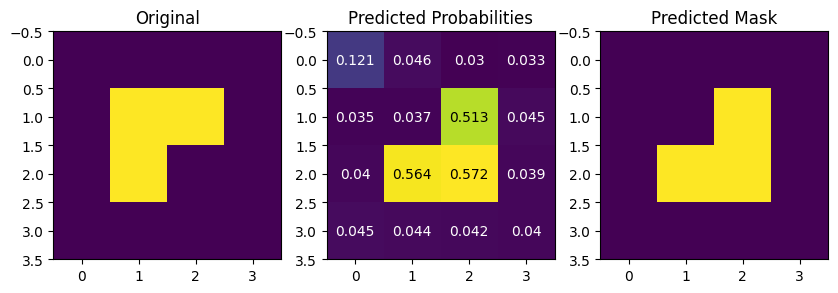

In [22]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize= (10,3*10))

ax1.imshow(dummpy_sample['labels'].squeeze(1)[0].cpu())
ax1.set_title("Original")

ax2.imshow(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu())
for (j,i),label in np.ndenumerate(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu()):
    if label < 0.5:
        color = 'white'
    else:
        color = 'black'
    ax2.text(i,j,round(label,3), color=color, ha='center',va='center')

ax2.set_title("Predicted Probabilities")

ax3.imshow((dummpy_sample['logits'].sigmoid() > 0.5).squeeze(1)[0].cpu())
ax3.set_title("Predicted Mask")
plt.show()

Проверяем на данном примере:

In [23]:
bce_loss_score = bce_loss(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_true_score = bce_true(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_torch_score = bce_torch(torch.sigmoid(dummpy_sample['logits'].cpu()), dummpy_sample['labels'].cpu().float())
bce_torch_with_logits_score = bce_torch_with_logits(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu().float())
assert np.isclose(bce_loss_score, bce_torch_score)
assert np.isclose(bce_loss_score, bce_torch_with_logits_score)
assert np.isclose(bce_true_score, bce_torch_score)
assert np.isclose(bce_true_score, bce_torch_with_logits_score)

## Шаг 4. Модель SegNet [2 балла]

Ваше задание здесь состоит в том, чтобы реализовать SegNet архитектуру.

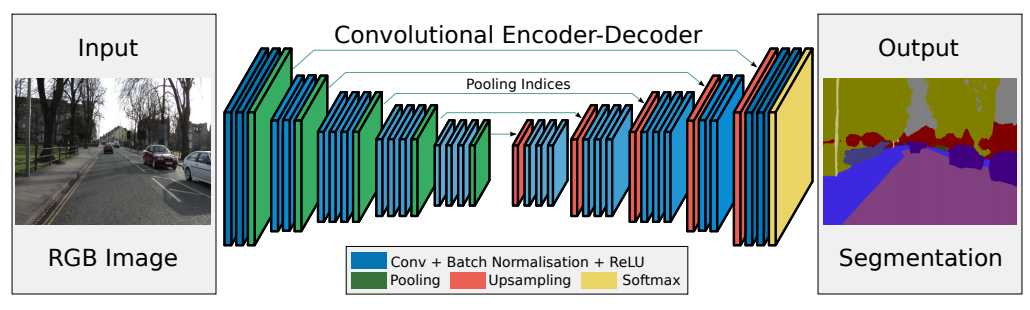

* Badrinarayanan, V., Kendall, A., & Cipolla, R. (2015). [SegNet: A deep convolutional
encoder-decoder architecture for image segmentation](https://arxiv.org/pdf/1511.00561.pdf)

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch.optim as optim
from time import time

from matplotlib import rcParams
rcParams['figure.figsize'] = (15,4)

Внимательно посмотрите из чего состоит модель и для чего выбраны те или иные блоки. Для этого скачаем и изучим feature extractor VGG-16, который лежит в основе SegNet.

In [25]:
model_vgg16 = models.vgg16(weights = models.VGG16_Weights.IMAGENET1K_V1)

In [26]:
model_vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Feature extractor VGG-16 состоит из 5 блоков:
- два блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d
- три блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d

В первом блоке - на входе три канала (по числу каналов в изображениях), которые конволюционный слой преобразует в 64 канала.

Во втором, третьем и четвертом блоках первый конволюционный слой удваивает количество каналов, а последующие конволюционные слои не меняют количество каналов.

В последнем блоке число каналов от слоя к слою не меняется.

Теперь напишем код одного блока энкодера нашей модели SegNet.  

In [27]:
# Параметрами блока будут:
# - количество каналов на входе
# - количество каналов на выходе
# - глубина блока (2 или 3, по количеству конволюционных слоев)
# - kernel_size и padding
#
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1):
        super(EncoderBlock, self).__init__() # инициируем экземляр класса, наследующего от nn.Module
        self.layers = nn.ModuleList() # в self.layers будем добавлять слои блока
        # дальше реализуем то, что на картинке выше обозначено Conv + Batch Normalization + ReLU
        self.layers.append(nn.Conv2d(in_channels = in_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
        self.layers.append(nn.BatchNorm2d(out_channels))
        self.layers.append(nn.ReLU(inplace=True))

        # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
        for i in range(depth-1):
            self.layers.append(nn.Conv2d(in_channels = out_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True) #добавляем MaxPool с индексами для последующего Unpooling

    # Обратите внимание: на вход метод forward() получает карту признаков (х),
    # а возвращает карту признаков и индексы для последующего Unpooling
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        x, indices = self.maxpooling(x)
        return x, indices


По аналогии напишите код одного блока декодера.

К карте признаков на входе каждого блока примеяется nn.MaxUnpool2d с индексами из симметричного блока энкодера. Затем повторяется связка Conv + Batch Normalization + ReLU. Количество каналов меняется зеркально блокам энкодера:
- в первом блоке декодера количество каналов не меняется
- во 2-4 блоках декодера количество каналов уменьшается в 2 раза после прохождения последнего конволюционного слоя
- на выходе из последнего блока декодера 1 канал

Обратите внимание, что после последней конволюции последнего блока декодера не применяется батч-нормализация и функция активации.

In [28]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth,
                 kernel_size=3, padding=1, last_block=False):
        super(DecoderBlock, self).__init__()

        self.layers = nn.ModuleList()

        for i in range(depth - 1):
            self.layers.append(nn.Conv2d(in_channels, in_channels,
                                         kernel_size, padding=padding))
            self.layers.append(nn.BatchNorm2d(in_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.layers.append(nn.Conv2d(in_channels, out_channels,
                                     kernel_size, padding=padding))

        if not last_block:
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.unpooling = nn.MaxUnpool2d(kernel_size=2, stride=2)

    def forward(self, x, indices):
        x = self.unpooling(x, indices)

        for layer in self.layers:
            x = layer(x)

        return x


Соединим блоки энкодера и декодера в модель SegNet:

In [29]:

class SegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, num_features=64) -> None:
        super(SegNet, self).__init__()

        # Encoder
        self.encoder0 = EncoderBlock(in_channels, num_features, depth=2)
        self.encoder1 = EncoderBlock(num_features, num_features * 2, depth=2)
        self.encoder2 = EncoderBlock(num_features * 2, num_features * 4, depth=3)
        self.encoder3 = EncoderBlock(num_features * 4, num_features * 8, depth=3)

        # Encoder bottleneck
        self.encoder4 = EncoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder bottleneck
        self.decoder0 = DecoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder
        self.decoder1 = DecoderBlock(num_features * 8, num_features * 4, depth=3)
        self.decoder2 = DecoderBlock(num_features * 4, num_features * 2, depth=3)
        self.decoder3 = DecoderBlock(num_features * 2, num_features, depth=2)
        self.decoder4 = DecoderBlock(num_features, out_channels, depth=2, last_block=True)

    def forward(self, x):
        # Encoder
        x, indices0 = self.encoder0(x)
        x, indices1 = self.encoder1(x)
        x, indices2 = self.encoder2(x)
        x, indices3 = self.encoder3(x)
        x, indices4 = self.encoder4(x)

        # Decoder
        x = self.decoder0(x, indices4)
        x = self.decoder1(x, indices3)
        x = self.decoder2(x, indices2)
        x = self.decoder3(x, indices1)
        output = self.decoder4(x, indices0)

        return output  # no activation


## Шаг 5. Тренировка модели [1 балл]

Напишите функции для обучения модели.

In [30]:
from tqdm.notebook import tqdm

In [31]:

def train_one_epoch(model, dataloader, optimizer, loss_fn):
    model.train()
    total_loss = 0

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_fn(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(dataloader.dataset)


@torch.no_grad()
def eval_one_epoch(model, dataloader, loss_fn):
    model.eval()
    total_loss = 0
    iou_score.reset()

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        total_loss += loss.item() * images.size(0)
        iou_score.update(torch.sigmoid(logits), masks.int())

    return total_loss / len(dataloader.dataset), iou_score.compute().item()


In [32]:

def train(model, train_dataloader, valid_dataloader, optimizer, loss_fn, epochs=15):
    best_iou = -1

    for epoch in tqdm(range(epochs)):
        train_loss = train_one_epoch(
            model, train_dataloader, optimizer, loss_fn
        )

        valid_loss, valid_iou = eval_one_epoch(
            model, valid_dataloader, loss_fn
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Valid Loss: {valid_loss:.4f} | "
            f"Valid IoU: {valid_iou:.4f}"
        )

        if valid_iou > best_iou:
            best_iou = valid_iou
            torch.save(model.state_dict(), "best_segnet.pth")

    print(f"Best IoU: {best_iou:.4f}")


Обучите модель **SegNet**. В качестве оптимайзера можно взять Adam.

In [33]:

model = SegNet().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

train(model, train_dataloader, valid_dataloader, optimizer, loss_fn, epochs=15)


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6749 | Valid Loss: 0.6743 | Valid IoU: 0.0000
Epoch 2/15 | Train Loss: 0.5876 | Valid Loss: 0.6473 | Valid IoU: 0.0000
Epoch 3/15 | Train Loss: 0.4738 | Valid Loss: 0.4893 | Valid IoU: 0.5469
Epoch 4/15 | Train Loss: 0.3672 | Valid Loss: 0.6220 | Valid IoU: 0.0297
Epoch 5/15 | Train Loss: 0.3512 | Valid Loss: 0.6047 | Valid IoU: 0.1973
Epoch 6/15 | Train Loss: 0.2997 | Valid Loss: 0.5129 | Valid IoU: 0.2800
Epoch 7/15 | Train Loss: 0.2734 | Valid Loss: 0.4795 | Valid IoU: 0.4029
Epoch 8/15 | Train Loss: 0.2524 | Valid Loss: 0.3828 | Valid IoU: 0.5833
Epoch 9/15 | Train Loss: 0.2400 | Valid Loss: 0.3751 | Valid IoU: 0.5944
Epoch 10/15 | Train Loss: 0.2218 | Valid Loss: 0.3765 | Valid IoU: 0.6326
Epoch 11/15 | Train Loss: 0.2152 | Valid Loss: 0.2856 | Valid IoU: 0.6733
Epoch 12/15 | Train Loss: 0.2340 | Valid Loss: 0.2865 | Valid IoU: 0.6484
Epoch 13/15 | Train Loss: 0.2101 | Valid Loss: 0.3635 | Valid IoU: 0.5696
Epoch 14/15 | Train Loss: 0.2169 | Valid Loss: 

## Шаг 6. Инференс [1 балл]

После обучения модели напишите функцию теста, воспользуйтесь лучшим чекпоинтом и протестируйте работу модели на тестовой выборке.

In [34]:

@torch.no_grad()
def test(model, dataloader, loss_fn):
    model.eval()
    iou_score.reset()
    total_loss = 0

    for images, masks in tqdm(dataloader):
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        total_loss += loss.item() * images.size(0)
        iou_score.update(torch.sigmoid(logits), masks.int())

    test_loss = total_loss / len(dataloader.dataset)
    test_iou = iou_score.compute().item()

    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test IoU: {test_iou:.4f}")

    return test_loss, test_iou


In [35]:

from pathlib import Path

assert Path("best_segnet.pth").exists(), "Чекпоинт не найден"

model = SegNet().to(device)
model.load_state_dict(
    torch.load("best_segnet.pth", map_location=device, weights_only=True)
)

test_loss, test_iou = test(
    model, test_dataloader, nn.BCEWithLogitsLoss()
)


  0%|          | 0/2 [00:00<?, ?it/s]

Test Loss: 0.3508
Test IoU: 0.6324


# Задания: Мир других лоссов!

## Пробуем другие функции потерь [2 балла]

В данном разделе вам потребуется имплементировать две функции потерь: DICE и Focal loss.


### Dice Loss

**1. Dice coefficient:** Учитывая две маски $X$ и $Y$, общая метрика для измерения расстояния между этими двумя масками задается следующим образом:

$$D(X,Y)=\frac{2|X\cap Y|}{|X|+|Y|}$$

В терминах матрицы ошибок она будет считаться следующим образом:

$$D(X,Y) = \frac{2TP}{2TP + FP + FN}$$

Эта функция не является дифференцируемой, но это необходимое свойство для градиентного спуска. В данном случае мы можем приблизить его с помощью:

$$\mathcal L_D(X,Y) = 1- D(X, Y)$$

**Hints** (!):

1. Не забудьте подумать о численной нестабильности, возникающей в математической формуле при ситуации, когда $\frac{0}{0}$, т.е. вам нужно добавить очень маленькое число, например $\epsilon = 1e^{-8}$, в обе части дроби при подсчете $D(X,Y)$:

$$D(X,Y) = \frac{2TP + ϵ}{2TP + FP + FN + ϵ}$$

2. Dice метрика(!), не лосс, считается похожим образом как IoU:

    2.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    2.2. Фиксируем порог, например threshold=0.5, и всему что ниже порога ставим значение 0, всему что выше 1. Получаем предсказанную маску из 0 и 1.

    2.3. Считаем TP, FP, FN

    2.4. Считаем DICE метрику по формуле

Вы можете прописать для себя функцию `dice_score()` и сравнить с результатами работы функции из библиотеки `torchmetrics`.

3. Но с метрикой есть проблема, что она не дифференцируема, и если вы захотите просто взять и прописать `dice_loss` = 1 - `dice_score`, Pytorch поругается на вас и скажет, что это недифференцируемая метрика. Чтобы посчитать dice_loss делаем следующие шаги:

    3.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    3.2. Здесь нам уже не нужно фиксировать порог, мы просто работаем с вероятностями. Значения вероятностей дифференцируемы и через них будут протекать градиенты.

    3.3. Считаем TP, FP, FN также как и в Dice метрике, только вместо маски, подаем вероятности.

    3.4. Считаем DICE метрику по формуле

    3.5. Считаем лосс как Loss = 1 - DICE

Итак, давайте сначала пропишем dice_score.

In [36]:

def dice_score(logits: torch.Tensor, labels: torch.Tensor, threshold: float = 0.5):
    probs = torch.sigmoid(logits)

    preds = (probs >= threshold).float()
    labels = labels.float()

    tp = (preds * labels).sum()
    fp = (preds * (1 - labels)).sum()
    fn = ((1 - preds) * labels).sum()

    eps = 1e-8
    score = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    return score


Проверим на корректность функцию dice_score:

In [37]:

from torchmetrics.classification import BinaryF1Score

# Заменили DiceScore на BinaryF1Score, так как он корректно
# обрабатывает вероятности с порогом 0.5 для бинарной сегментации.
dice = BinaryF1Score(threshold=0.5).to(device)

dice(dummpy_sample['logits'].sigmoid(),dummpy_sample['labels'].int())


tensor(0.6667, device='cuda:0')

In [38]:
'''
если вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():

from torchmetrics.classification import Dice

dice = Dice(average='micro').to(device)

'''

"\nесли вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():\n\nfrom torchmetrics.classification import Dice\n\ndice = Dice(average='micro').to(device)\n\n"

In [39]:
assert dice(dummpy_sample['logits'].sigmoid(), dummpy_sample['labels'].to(int)) == dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

Давайте теперь пропишем лосс и воспользуемся библиотекой `segmentation-models-pytorch`, чтобы убедиться в корректности нашей функции.

In [40]:
def dice_loss(logits: torch.Tensor, labels: torch.Tensor):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    tp = (probs * labels).sum()
    fp = (probs * (1 - labels)).sum()
    fn = ((1 - probs) * labels).sum()

    eps = 1e-8
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    loss = 1 - dice
    return loss


Проверка на корректность:

In [41]:
# проверьте, что у вас установлена библиотека
!pip install segmentation-models-pytorch

In [42]:
from segmentation_models_pytorch.losses import DiceLoss
dice_loss_torch = DiceLoss(mode='binary')
dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756, device='cuda:0')

In [43]:
assert dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int)) == dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

### Focal Loss

[**2. Focal loss:**](https://arxiv.org/pdf/1708.02002.pdf)

Окей, мы уже с вами умеем делать BCE loss:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Проблема с этой потерей заключается в том, что она имеет тенденцию приносить пользу классу **большинства** (фоновому) по отношению к классу **меньшинства** ( переднему). Поэтому обычно применяются весовые коэффициенты к каждому классу:

$$\mathcal L_{wBCE}(y, \hat y) = -\sum_i \alpha_i\left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Традиционно вес $\alpha_i$ определяется как обратная частота класса этого пикселя $i$, так что наблюдения миноритарного класса весят больше по отношению к классу большинства.


Из оригинальной статьи по [Focal Loss](https://arxiv.org/pdf/1708.02002.pdf):

$$p_t = \sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)$$

$$\mathcal L_{focal}(y, \hat y) = (1 - p_t)^{\gamma} \mathcal L_{BCE}(y_i, \hat y_i).$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - p_t)^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - (\sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)))^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

In [44]:
def focal_loss(y_real, y_pred, eps=1e-8, gamma=2):
    probs = torch.sigmoid(y_pred)

    bce = F.binary_cross_entropy_with_logits(
        y_pred, y_real, reduction='none'
    )

    pt = probs * y_real + (1 - probs) * (1 - y_real)

    loss = bce * ((1 - pt) ** gamma)

    return loss.sum()


Проверка корректности функции:

In [45]:
from torchvision.ops import sigmoid_focal_loss
sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum')

tensor(3.6161, device='cuda:0')

In [46]:
assert sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum') == focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0)

## [BONUS] Мир сегментационных лоссов [5 баллов]

В данном блоке предлагаем вам написать одну функцию потерь самостоятельно. Для этого необходимо прочитать статью и имплементировать ее, и провести численное сравнение с предыдущими функциями.
 **ВАЖНО:** за имплементацию одного лосса выдается только один балл. Чтобы получить все 5 баллов, будет необходимо имплементировать все 5 лоссов.

* [Physiological Inspired Deep Neural Networks for Emotion Recognition](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8472816&tag=1)". IEEE Access, 6, 53930-53943.

* [Boundary loss for highly unbalanced segmentation](https://arxiv.org/abs/1812.07032)

* [Tversky loss function for image segmentation using 3D fully convolutional deep networks](https://arxiv.org/abs/1706.05721)

* [Correlation Maximized Structural Similarity Loss for Semantic Segmentation](https://arxiv.org/abs/1910.08711)

* [Topology-Preserving Deep Image Segmentation](https://papers.nips.cc/paper/8803-topology-preserving-deep-image-segmentation)

In [47]:
import torch
import torch.nn.functional as F
import numpy as np

from scipy.ndimage import distance_transform_edt


Physiological Inspired Deep Neural Networks for Emotion Recognition


In [48]:
def physiological_loss(class_logits, class_labels, relevance_map,
                       lam=0.1, gamma=0.1):
    classification = F.cross_entropy(
        class_logits, class_labels.long(), reduction='sum'
    )

    sparsity = relevance_map.abs().mean(dim=(1, 2, 3)).sum()

    dh = (relevance_map[:, :, 1:, :] -
          relevance_map[:, :, :-1, :]).abs().sum()

    dw = (relevance_map[:, :, :, 1:] -
          relevance_map[:, :, :, :-1]).abs().sum()

    h, w = relevance_map.shape[-2:]
    contiguity = (dh + dw) / (h * w)

    return classification + lam * (
        sparsity + gamma * contiguity
    )


Boundary Loss

In [49]:
def signed_distance_map(labels):
    masks = labels.detach().cpu().numpy() > 0.5
    distances = np.zeros_like(masks, dtype=np.float32)

    for b in range(masks.shape[0]):
        for c in range(masks.shape[1]):
            mask = masks[b, c]

            if mask.any() and (~mask).any():
                outside = distance_transform_edt(~mask) * (~mask)
                inside = (distance_transform_edt(mask) - 1) * mask

                distances[b, c] = outside - inside

    return torch.as_tensor(
        distances, device=labels.device, dtype=labels.dtype
    )


def boundary_loss(logits, labels):
    labels = labels.float()
    probs = torch.sigmoid(logits)

    distances = signed_distance_map(labels)

    return (probs * distances).mean()


Tversky Loss

In [50]:
def tversky_loss(logits, labels, alpha=0.3, beta=0.7, eps=1e-8):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    dims = (1, 2, 3)

    tp = (probs * labels).sum(dim=dims)
    fp = (probs * (1 - labels)).sum(dim=dims)
    fn = ((1 - probs) * labels).sum(dim=dims)

    tversky = (tp + eps) / (
        tp + alpha * fp + beta * fn + eps
    )

    return 1 - tversky.mean()


Structural Similarity Loss

In [51]:
def structural_similarity_loss(
    logits, labels, window_size=3, sigma=1.5,
    beta=0.1, lam=0.5, c4=0.01
):
    labels = labels.float()
    probs = torch.sigmoid(logits)

    channels = probs.shape[1]
    radius = window_size // 2

    x = torch.arange(
        window_size, device=logits.device, dtype=logits.dtype
    ) - radius

    g = torch.exp(-0.5 * (x / sigma) ** 2)
    g = g / g.sum()

    kernel_2d = torch.outer(g, g)
    kernel = kernel_2d[None, None].expand(
        channels, 1, -1, -1
    ).contiguous()

    def local_stats(t):
        padded = F.pad(t, (radius,) * 4, mode='reflect')

        mean = F.conv2d(padded, kernel, groups=channels)
        mean_sq = F.conv2d(
            padded.square(), kernel, groups=channels
        )

        std = (mean_sq - mean.square()).clamp_min(0).sqrt()
        return mean, std

    mean_y, std_y = local_stats(labels)
    mean_p, std_p = local_stats(probs)

    error = torch.abs(
        (labels - mean_y + c4) / (std_y + c4)
        - (probs - mean_p + c4) / (std_p + c4)
    )

    center = kernel_2d[radius, radius]
    e_max = 2 * (1 - center) / (
        torch.sqrt(center * (1 - center)) + c4
    )

    hard = (error > beta * e_max).float()

    weights = error.detach() * hard

    bce = F.binary_cross_entropy_with_logits(
        logits, labels, reduction='none'
    )

    ssl = (weights * bce).sum() / hard.sum().clamp_min(1)

    return lam * bce.mean() + (1 - lam) * ssl


Topological Loss

In [52]:
!pip install gudhi

In [53]:
import gudhi

def persistence_pairs(image):
    values = 1 - image.detach().cpu().numpy()

    complex_ = gudhi.CubicalComplex(
        top_dimensional_cells=values
    )
    complex_.persistence(
        homology_coeff_field=2, min_persistence=0
    )

    finite, essential = complex_.cofaces_of_persistence_pairs()
    flat = values.ravel()

    result = []

    for dim in (0, 1):
        pairs = finite[dim] if dim < len(finite) else []
        features = []

        for birth, death in pairs:
            b = float(flat[birth])
            d = float(flat[death])

            if d > b:
                features.append((int(birth), int(death), b, d))

        result.append(features)

    essential_h0 = (
        essential[0] if len(essential) > 0 else []
    )

    return result, essential_h0


def topological_loss(logits, labels, patch_size=64,
                     min_persistence=0.03):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    assert probs.ndim == 4 and probs.shape[1] == 1

    total = probs.sum() * 0.0
    count = 0

    for batch in range(probs.shape[0]):
        h, w = probs.shape[-2:]

        for y in range(0, h, patch_size):
            for x in range(0, w, patch_size):
                pred = probs[
                    batch, 0, y:y + patch_size, x:x + patch_size
                ]
                gt = labels[
                    batch, 0, y:y + patch_size, x:x + patch_size
                ]

                pred_pairs, pred_essential = persistence_pairs(pred)
                gt_pairs, _ = persistence_pairs(gt)

                flat = pred.reshape(-1)

                if gt.max().item() > 0.5 and len(pred_essential):
                    birth = int(pred_essential[0])
                    total = total + (1 - flat[birth]).square()
                    count += 1

                for dim in (0, 1):
                    target_count = sum(
                        (d - b) > 0.5
                        for _, _, b, d in gt_pairs[dim]
                    )

                    features = sorted(
                        pred_pairs[dim],
                        key=lambda p: p[2] ** 2 + (p[3] - 1) ** 2
                    )

                    for i, (birth, death, b, d) in enumerate(features):
                        pb = flat[birth]
                        pd = flat[death]

                        if i < target_count:
                            total = total + (1 - pb).square() + pd.square()
                            count += 1

                        elif (d - b) > min_persistence:
                            total = total + 0.5 * (pb - pd).square()
                            count += 1

    return total / max(count, 1)


## Обучите SegNet на новых лоссах

**Задание**: обучите SegNet на новых лоссах и сравните все три лосса:
*   При каком лоссе модель сходится быстрее?
*   При каком лоссе модель выдает наилучшую метрику?

Напишите развернутый ответ на вопросы.



In [54]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

EPOCHS = 15
LR = 1e-3
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

loss_functions = {
    "BCE": F.binary_cross_entropy_with_logits,
    "Dice": dice_loss,
    "Focal": lambda logits, labels: focal_loss(labels, logits) / logits.numel()
}

checkpoints_dir = Path("segnet_comparison")
checkpoints_dir.mkdir(exist_ok=True)


In [55]:
import time

def train_experiment(name, loss_fn, model_class=SegNet):
    set_seed()

    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    history = {
        "train_loss": [],
        "val_bce": [],
        "val_iou": [],
        "val_dice": [],
        "epoch_seconds": []
    }

    best_iou = -1
    best_epoch = 0

    for epoch in tqdm(range(EPOCHS), desc=f"{model_class.__name__} — {name}"):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        model.train()
        total_loss = 0
        total_images = 0

        for images, masks in train_dataloader:
            images = images.to(device).float()
            masks = masks.to(device).float()

            optimizer.zero_grad()

            logits = model(images)
            loss = loss_fn(logits, masks)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)

        train_loss = total_loss / total_images

        model.eval()
        tp = fp = fn = 0
        total_bce = 0
        total_pixels = 0

        with torch.no_grad():
            for images, masks in valid_dataloader:
                images = images.to(device).float()
                masks = masks.to(device).float()

                logits = model(images)

                preds = torch.sigmoid(logits) >= 0.5
                targets = masks >= 0.5

                tp += (preds & targets).sum().item()
                fp += (preds & ~targets).sum().item()
                fn += (~preds & targets).sum().item()

                total_bce += F.binary_cross_entropy_with_logits(
                    logits, masks, reduction="sum"
                ).item()

                total_pixels += masks.numel()

        eps = 1e-8

        iou = (tp + eps) / (tp + fp + fn + eps)
        dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
        val_bce = total_bce / total_pixels

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        history["train_loss"].append(train_loss)
        history["val_bce"].append(val_bce)
        history["val_iou"].append(iou)
        history["val_dice"].append(dice)
        history["epoch_seconds"].append(elapsed)

        if iou > best_iou:
            best_iou = iou
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoints_dir / (
                    f"{model_class.__name__.lower()}_{name.lower()}.pth"
                )
            )

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val IoU: {iou:.4f} | "
            f"Val Dice: {dice:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    history["best_iou"] = best_iou
    history["best_epoch"] = best_epoch
    history["total_seconds"] = sum(history["epoch_seconds"])
    history["avg_epoch_seconds"] = (
        history["total_seconds"] / EPOCHS
    )

    print(
        f"\n{model_class.__name__} — {name} | "
        f"Best IoU: {best_iou:.4f} | "
        f"Best Epoch: {best_epoch} | "
        f"Total Time: {history['total_seconds']:.1f}s"
    )

    del model, optimizer

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return history


In [56]:
histories = {}

for name, loss_fn in loss_functions.items():
    print(f"\n{'=' * 40}")
    print(f"Training SegNet with {name} Loss")
    print(f"{'=' * 40}")

    histories[name] = train_experiment(name, loss_fn)



Training SegNet with BCE Loss


SegNet — BCE:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6557 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.3s
Epoch 2/15 | Train Loss: 0.5896 | Val IoU: 0.0008 | Val Dice: 0.0017 | Time: 5.3s
Epoch 3/15 | Train Loss: 0.4445 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.3310 | Val IoU: 0.0179 | Val Dice: 0.0351 | Time: 5.3s
Epoch 5/15 | Train Loss: 0.2995 | Val IoU: 0.2805 | Val Dice: 0.4381 | Time: 5.3s
Epoch 6/15 | Train Loss: 0.2687 | Val IoU: 0.2854 | Val Dice: 0.4441 | Time: 5.3s
Epoch 7/15 | Train Loss: 0.2348 | Val IoU: 0.3855 | Val Dice: 0.5565 | Time: 5.3s
Epoch 8/15 | Train Loss: 0.2459 | Val IoU: 0.5160 | Val Dice: 0.6807 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.2252 | Val IoU: 0.5969 | Val Dice: 0.7476 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.2316 | Val IoU: 0.5860 | Val Dice: 0.7389 | Time: 5.1s
Epoch 11/15 | Train Loss: 0.2067 | Val IoU: 0.6209 | Val Dice: 0.7661 | Time: 5.1s
Epoch 12/15 | Train Loss: 0.2082 | Val IoU: 0.5856 | Val Dice: 0.7386 | Time: 5.1s
Epoch 13/15 |

SegNet — Dice:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6135 | Val IoU: 0.0000 | Val Dice: 0.0001 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.5773 | Val IoU: 0.2938 | Val Dice: 0.4542 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.5095 | Val IoU: 0.2939 | Val Dice: 0.4543 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.4468 | Val IoU: 0.1061 | Val Dice: 0.1918 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.3946 | Val IoU: 0.3028 | Val Dice: 0.4648 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.3376 | Val IoU: 0.2935 | Val Dice: 0.4539 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.2560 | Val IoU: 0.2849 | Val Dice: 0.4435 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2321 | Val IoU: 0.2899 | Val Dice: 0.4495 | Time: 5.3s
Epoch 9/15 | Train Loss: 0.2016 | Val IoU: 0.4925 | Val Dice: 0.6599 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.1870 | Val IoU: 0.5887 | Val Dice: 0.7411 | Time: 5.1s
Epoch 11/15 | Train Loss: 0.1617 | Val IoU: 0.6143 | Val Dice: 0.7611 | Time: 5.1s
Epoch 12/15 | Train Loss: 0.1439 | Val IoU: 0.6475 | Val Dice: 0.7861 | Time: 5.1s
Epoch 13/15 |

SegNet — Focal:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.1895 | Val IoU: 0.0005 | Val Dice: 0.0011 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.1519 | Val IoU: 0.0026 | Val Dice: 0.0051 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.1244 | Val IoU: 0.0016 | Val Dice: 0.0032 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.1388 | Val IoU: 0.0000 | Val Dice: 0.0001 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.1332 | Val IoU: 0.0829 | Val Dice: 0.1532 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.1184 | Val IoU: 0.0501 | Val Dice: 0.0955 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.1048 | Val IoU: 0.0951 | Val Dice: 0.1737 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.0978 | Val IoU: 0.2290 | Val Dice: 0.3726 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.0884 | Val IoU: 0.4780 | Val Dice: 0.6468 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.0817 | Val IoU: 0.5638 | Val Dice: 0.7211 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.0838 | Val IoU: 0.6096 | Val Dice: 0.7574 | Time: 5.1s
Epoch 12/15 | Train Loss: 0.0789 | Val IoU: 0.6205 | Val Dice: 0.7658 | Time: 5.2s
Epoch 13/15 |

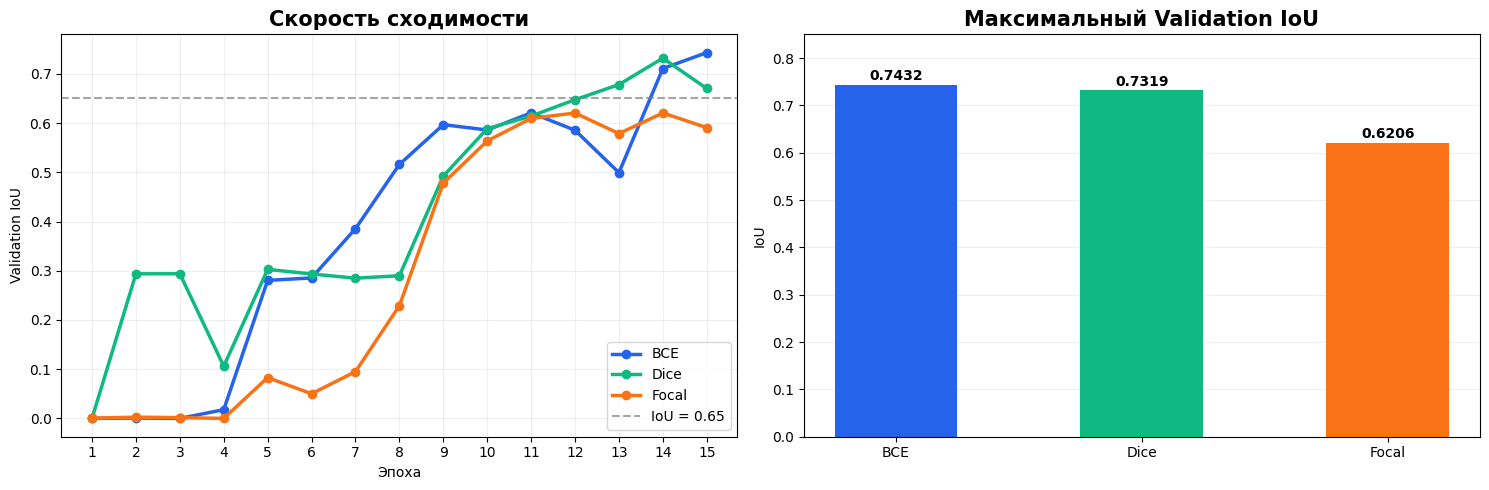

In [57]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = {
    "BCE": "#2563EB",
    "Dice": "#10B981",
    "Focal": "#F97316"
}

ax = axes[0]

for name, h in histories.items():
    epochs = range(1, len(h["val_iou"]) + 1)
    ax.plot(epochs, h["val_iou"], label=name,
            color=colors[name], linewidth=2.5, marker="o")

ax.axhline(0.65, color="gray", linestyle="--",
           alpha=0.7, label="IoU = 0.65")

ax.set_title("Скорость сходимости", fontsize=15, fontweight="bold")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Validation IoU")
ax.set_xticks(range(1, EPOCHS + 1))
ax.legend()
ax.grid(alpha=0.2)

ax = axes[1]

names = list(histories.keys())
scores = [histories[n]["best_iou"] for n in names]

bars = ax.bar(names, scores,
              color=[colors[n] for n in names], width=0.5)

for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width() / 2,
            score + 0.01, f"{score:.4f}",
            ha="center", fontweight="bold")

ax.set_title("Максимальный Validation IoU", fontsize=15, fontweight="bold")
ax.set_ylabel("IoU")
ax.set_ylim(0, 0.85)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### 1. При каком лоссе модель сходится быстрее?

По результатам эксперимента Dice Loss быстрее остальных достигает IoU 0.65  примерно на 12-й эпохе, тогда как BCE Loss достигает этого уровня на 14-й эпохе, а Focal Loss не достигает его за 15 эпох.

Это можно объяснить тем, что Dice Loss непосредственно оптимизирует перекрытие предсказанной и правильной масок, что особенно полезно в задачах сегментации. В отличие от BCE, который оценивает ошибки каждого пикселя, Dice Loss ориентирован на качество выделения объекта в целом.

### 2. При каком лоссе модель выдаёт наилучшую метрику?

Наилучший результат показал BCE Loss с Validation IoU 0.7432, тогда как Dice Loss достиг 0.7319, а Focal Loss  0.6206.

BCE Loss обеспечивает обучающий сигнал для каждого пикселя, что, вероятно, позволило модели более эффективно корректировать предсказания на всей маске. Dice Loss показал близкий результат, уступив BCE всего на 0.0113 IoU.

Focal Loss оказался заметно менее эффективным. Возможно, уменьшение вклада легко классифицируемых пикселей и концентрация на сложных примерах замедлили улучшение общего качества сегментации при выбранных параметрах и ограниченном количестве эпох.

Таким образом, Dice Loss быстрее достигает заданного уровня качества, однако BCE Loss обеспечивает наилучший максимальный Validation IoU. Focal Loss в данном эксперименте показал худший результат среди трёх функций потерь.

# Задание: Новая модель!

## Модель U-Net [2 балла]

[**U-Net**](https://arxiv.org/abs/1505.04597) — это архитектура нейронной сети, которая получает изображение и выводит его. Первоначально он был задуман для семантической сегментации (как мы ее будем использовать), но он настолько успешен, что с тех пор используется в других контекстах. Получая на вход медицинское изображение, он выведет изображение в оттенках серого, где интенсивность каждого пикселя зависит от вероятности того, что этот пиксель принадлежит интересующей нас области.

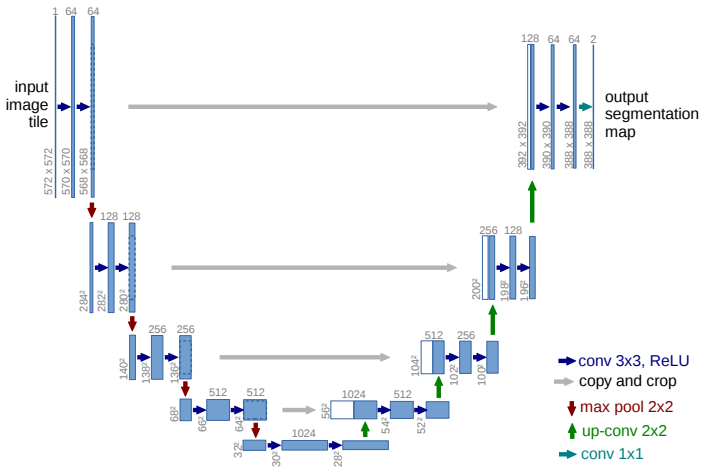

У нас в архитектуре все так же существует энкодер и декодер, как в **SegNet**, но отличительной особеностью данной модели являются *skip-conenctions*, соединяющие части декодера и энкодера. То есть для того чтобы передать на вход декодера тензор, мы конкатенируем симметричный выход с энкодера и выход предыдущего слоя декодера.

* Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "[U-Net: Convolutional networks for biomedical image segmentation.](https://arxiv.org/pdf/1505.04597.pdf)" International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

В оригинальной статье авторы не использовали padding внутри модели (это видно по тому, что размеры карты признаков уменьшаются на 2 каждый раз при движении от слоя к слою). При этом размеры входных изображений авторы единоразово увеличили при помощи mirror padding.

В этом домашнем задании вы можете применить альтернативный подход - сохранять размеры карт признаков при помощью padding = 1 во внутренних слоях.  

In [58]:
import torch.nn.functional as F
import torch.nn as nn

Для реализации UNet вы можете написать классы блоков энкодера и декодера отдельно, как мы сделали при реализации SegNet.

In [59]:
class UNet(nn.Module):
    def __init__(self, n_class=1):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.enc3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.enc4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = nn.Sequential(
            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.out_conv = nn.Conv2d(32, n_class, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + skip-connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        output = self.out_conv(d1)
        return output


In [60]:
unet_model = UNet().to(device)

## Обучите UNet

Задание: обучите UNet на всех трех лоссах: BCE, Dice, Focal и сравните результаты с SegNet:
*   Какая модель дает лучшие значения по метрике?
*   Какая модель дает лучшие значения по лоссам?
*   Какая модель обучается быстрее?
*   Сравните визуально результаты SegNet и UNet.

Напишите развернутый ответ на вопросы.



In [61]:
unet_histories = {}

for name, loss_fn in loss_functions.items():
    print(f"\nTraining UNet with {name} Loss")

    unet_histories[name] = train_experiment(
        name,
        loss_fn,
        model_class=UNet
    )



Training UNet with BCE Loss


UNet — BCE:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.5938 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.6s
Epoch 2/15 | Train Loss: 0.4513 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 3/15 | Train Loss: 0.4008 | Val IoU: 0.3444 | Val Dice: 0.5124 | Time: 2.5s
Epoch 4/15 | Train Loss: 0.3857 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.3573 | Val IoU: 0.3766 | Val Dice: 0.5471 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.3313 | Val IoU: 0.4744 | Val Dice: 0.6435 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.3123 | Val IoU: 0.3497 | Val Dice: 0.5182 | Time: 2.5s
Epoch 8/15 | Train Loss: 0.3050 | Val IoU: 0.4699 | Val Dice: 0.6394 | Time: 2.5s
Epoch 9/15 | Train Loss: 0.2866 | Val IoU: 0.6426 | Val Dice: 0.7824 | Time: 2.6s
Epoch 10/15 | Train Loss: 0.2798 | Val IoU: 0.7334 | Val Dice: 0.8462 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.2810 | Val IoU: 0.7464 | Val Dice: 0.8548 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.2566 | Val IoU: 0.7014 | Val Dice: 0.8245 | Time: 2.5s
Epoch 13/15 |

UNet — Dice:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.5005 | Val IoU: 0.0132 | Val Dice: 0.0260 | Time: 2.6s
Epoch 2/15 | Train Loss: 0.3951 | Val IoU: 0.0007 | Val Dice: 0.0015 | Time: 2.5s
Epoch 3/15 | Train Loss: 0.3721 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.6s
Epoch 4/15 | Train Loss: 0.3474 | Val IoU: 0.0025 | Val Dice: 0.0050 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.3335 | Val IoU: 0.0641 | Val Dice: 0.1205 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.3157 | Val IoU: 0.2921 | Val Dice: 0.4522 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.2978 | Val IoU: 0.3329 | Val Dice: 0.4996 | Time: 2.5s
Epoch 8/15 | Train Loss: 0.2820 | Val IoU: 0.6702 | Val Dice: 0.8026 | Time: 2.6s
Epoch 9/15 | Train Loss: 0.2723 | Val IoU: 0.5793 | Val Dice: 0.7336 | Time: 2.5s
Epoch 10/15 | Train Loss: 0.2642 | Val IoU: 0.6546 | Val Dice: 0.7913 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.2663 | Val IoU: 0.6219 | Val Dice: 0.7669 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.2345 | Val IoU: 0.7647 | Val Dice: 0.8666 | Time: 2.5s
Epoch 13/15 |

UNet — Focal:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.1499 | Val IoU: 0.0005 | Val Dice: 0.0010 | Time: 2.5s
Epoch 2/15 | Train Loss: 0.0998 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 3/15 | Train Loss: 0.0857 | Val IoU: 0.0014 | Val Dice: 0.0027 | Time: 2.6s
Epoch 4/15 | Train Loss: 0.0805 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.0720 | Val IoU: 0.0532 | Val Dice: 0.1011 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.0659 | Val IoU: 0.3178 | Val Dice: 0.4823 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.0617 | Val IoU: 0.1825 | Val Dice: 0.3087 | Time: 2.5s
Epoch 8/15 | Train Loss: 0.0553 | Val IoU: 0.5168 | Val Dice: 0.6814 | Time: 2.5s
Epoch 9/15 | Train Loss: 0.0549 | Val IoU: 0.3239 | Val Dice: 0.4893 | Time: 2.5s
Epoch 10/15 | Train Loss: 0.0568 | Val IoU: 0.4049 | Val Dice: 0.5764 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.0547 | Val IoU: 0.4397 | Val Dice: 0.6108 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.0505 | Val IoU: 0.6052 | Val Dice: 0.7541 | Time: 2.5s
Epoch 13/15 |

In [62]:
results = []

for model_name, model_histories in {
    "SegNet": histories,
    "UNet": unet_histories
}.items():
    for loss_name, h in model_histories.items():
        results.append({
            "Model": model_name,
            "Loss": loss_name,
            "Best IoU": h["best_iou"],
            "Best Dice": h["val_dice"][h["best_epoch"] - 1],
            "Best Epoch": h["best_epoch"],
            "Val BCE": h["val_bce"][h["best_epoch"] - 1]
        })

df = pd.DataFrame(results)
display(df.sort_values("Best IoU", ascending=False).round(4))


,Model,Loss,Best IoU,Best Dice,Best Epoch,Val BCE
4,UNet,Dice,0.8244,0.9038,15,0.2115
5,UNet,Focal,0.7986,0.8880,15,0.2723
3,UNet,BCE,0.7639,0.8661,13,0.2308
0,SegNet,BCE,0.7432,0.8527,15,0.2443
1,SegNet,Dice,0.7319,0.8452,14,0.5029
2,SegNet,Focal,0.6206,0.7659,14,0.3737


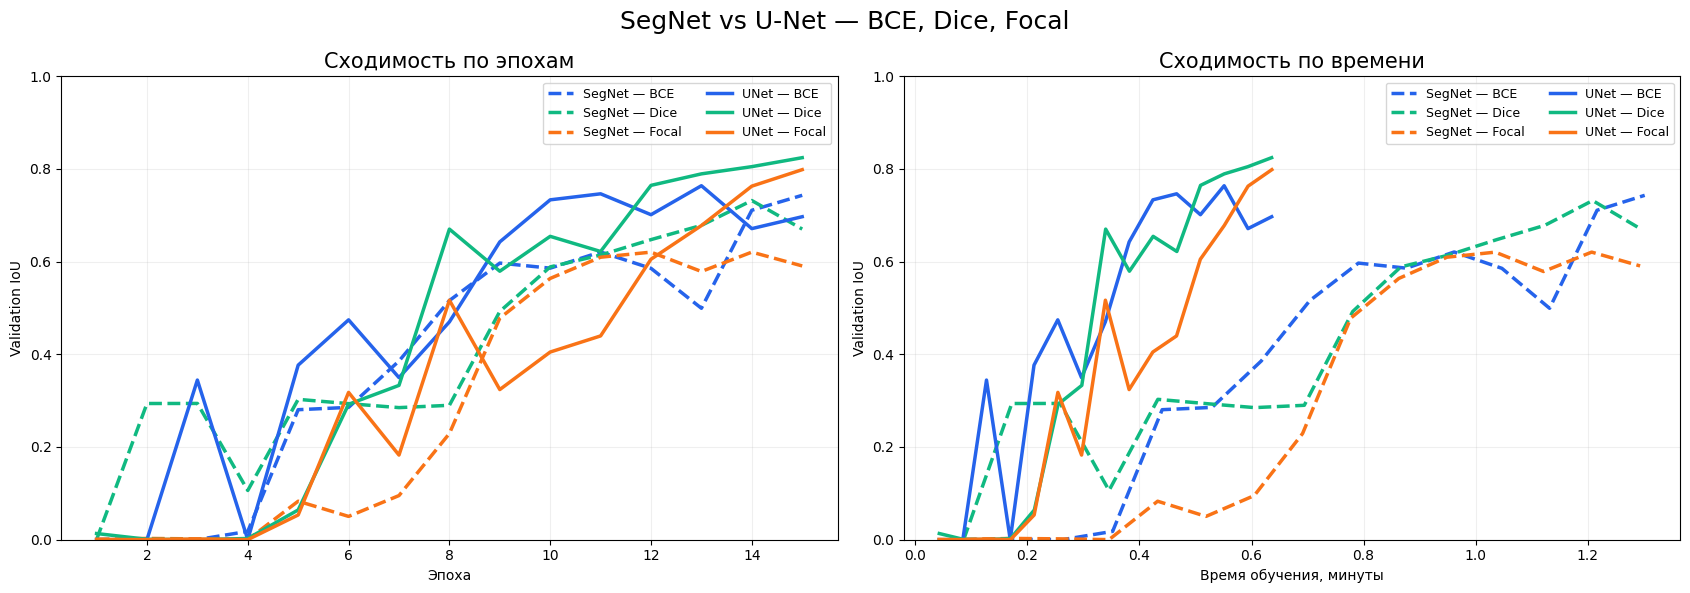

In [63]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

colors = {
    "BCE": "#2563EB",
    "Dice": "#10B981",
    "Focal": "#F97316"
}

all_histories = {
    "SegNet": histories,
    "UNet": unet_histories
}

for model_name, model_histories in all_histories.items():
    for loss_name, h in model_histories.items():
        epochs = np.arange(1, len(h["val_iou"]) + 1)
        elapsed_minutes = np.cumsum(h["epoch_seconds"]) / 60

        style = "-" if model_name == "UNet" else "--"
        label = f"{model_name} — {loss_name}"

        axes[0].plot(
            epochs, h["val_iou"],
            label=label,
            color=colors[loss_name],
            linestyle=style,
            linewidth=2.5
        )

        axes[1].plot(
            elapsed_minutes, h["val_iou"],
            label=label,
            color=colors[loss_name],
            linestyle=style,
            linewidth=2.5
        )

axes[0].set_title("Сходимость по эпохам", fontsize=15)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Validation IoU")

axes[1].set_title("Сходимость по времени", fontsize=15)
axes[1].set_xlabel("Время обучения, минуты")
axes[1].set_ylabel("Validation IoU")

for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9, ncol=2)
    ax.set_ylim(0, 1)

fig.suptitle("SegNet vs U-Net — BCE, Dice, Focal", fontsize=18)
plt.tight_layout()
plt.show()


### 1. Какая модель даёт лучшие значения по метрике?

Наилучший результат показала U-Net с Dice Loss: Validation IoU = 0.8244 и Dice Score = 0.9038.

Для сравнения, лучший результат SegNet получен с BCE Loss: IoU = 0.7432 и Dice Score = 0.8527.

Это можно объяснить архитектурой U-Net, которая использует skip-connections для передачи карт признаков из энкодера в декодер. Благодаря этому модель лучше сохраняет пространственную информацию, необходимую для точной сегментации объектов. Dice Loss дополнительно способствует улучшению качества, поскольку непосредственно оптимизирует перекрытие предсказанной и правильной масок.

### 2. Какая модель даёт лучшие значения по лоссам?

Минимальное значение Validation BCE также получила U-Net с Dice Loss 0.2115. Для сравнения, U-Net с BCE Loss получила 0.2308, а лучший результат SegNet по этой ошибке составил 0.2443.

При использовании одинаковых функций потерь U-Net показала меньшие значения Validation BCE во всех трёх экспериментах.

Таким образом, U-Net эффективнее минимизировала ошибку на валидационной выборке. При этом напрямую сравнивать значения разных обучающих лоссов некорректно, поэтому для общего сравнения использовалась единая метрика Validation BCE.

### 3. Какая модель обучается быстрее?

U-Net обучается заметно быстрее SegNet как по количеству эпох до достижения высокого IoU, так и по фактическому времени.

По графикам видно, что U-Net с Dice Loss достигает IoU выше 0.65 уже примерно на 8-й эпохе, тогда как SegNet достигает сопоставимого качества значительно позже.

Также полный цикл из 15 эпох для U-Net занимает примерно 0.6 минуты, а для SegNet — около 1.3 минуты.

Таким образом, в данном эксперименте U-Net не только быстрее достигает высокого качества сегментации, но и требует меньше времени на обучение.

### Общий вывод

По результатам проведённых экспериментов U-Net оказалась эффективнее SegNet по всем основным показателям. Лучший результат обеспечило сочетание U-Net и Dice Loss: IoU = 0.8244 и Dice Score = 0.9038. При этом U-Net быстрее обучалась и показала меньшую ошибку на валидационной выборке.

Полученные результаты подтверждают преимущество U-Net в данном эксперименте, однако для более надёжного сравнения желательно провести несколько запусков с разными случайными инициализациями.

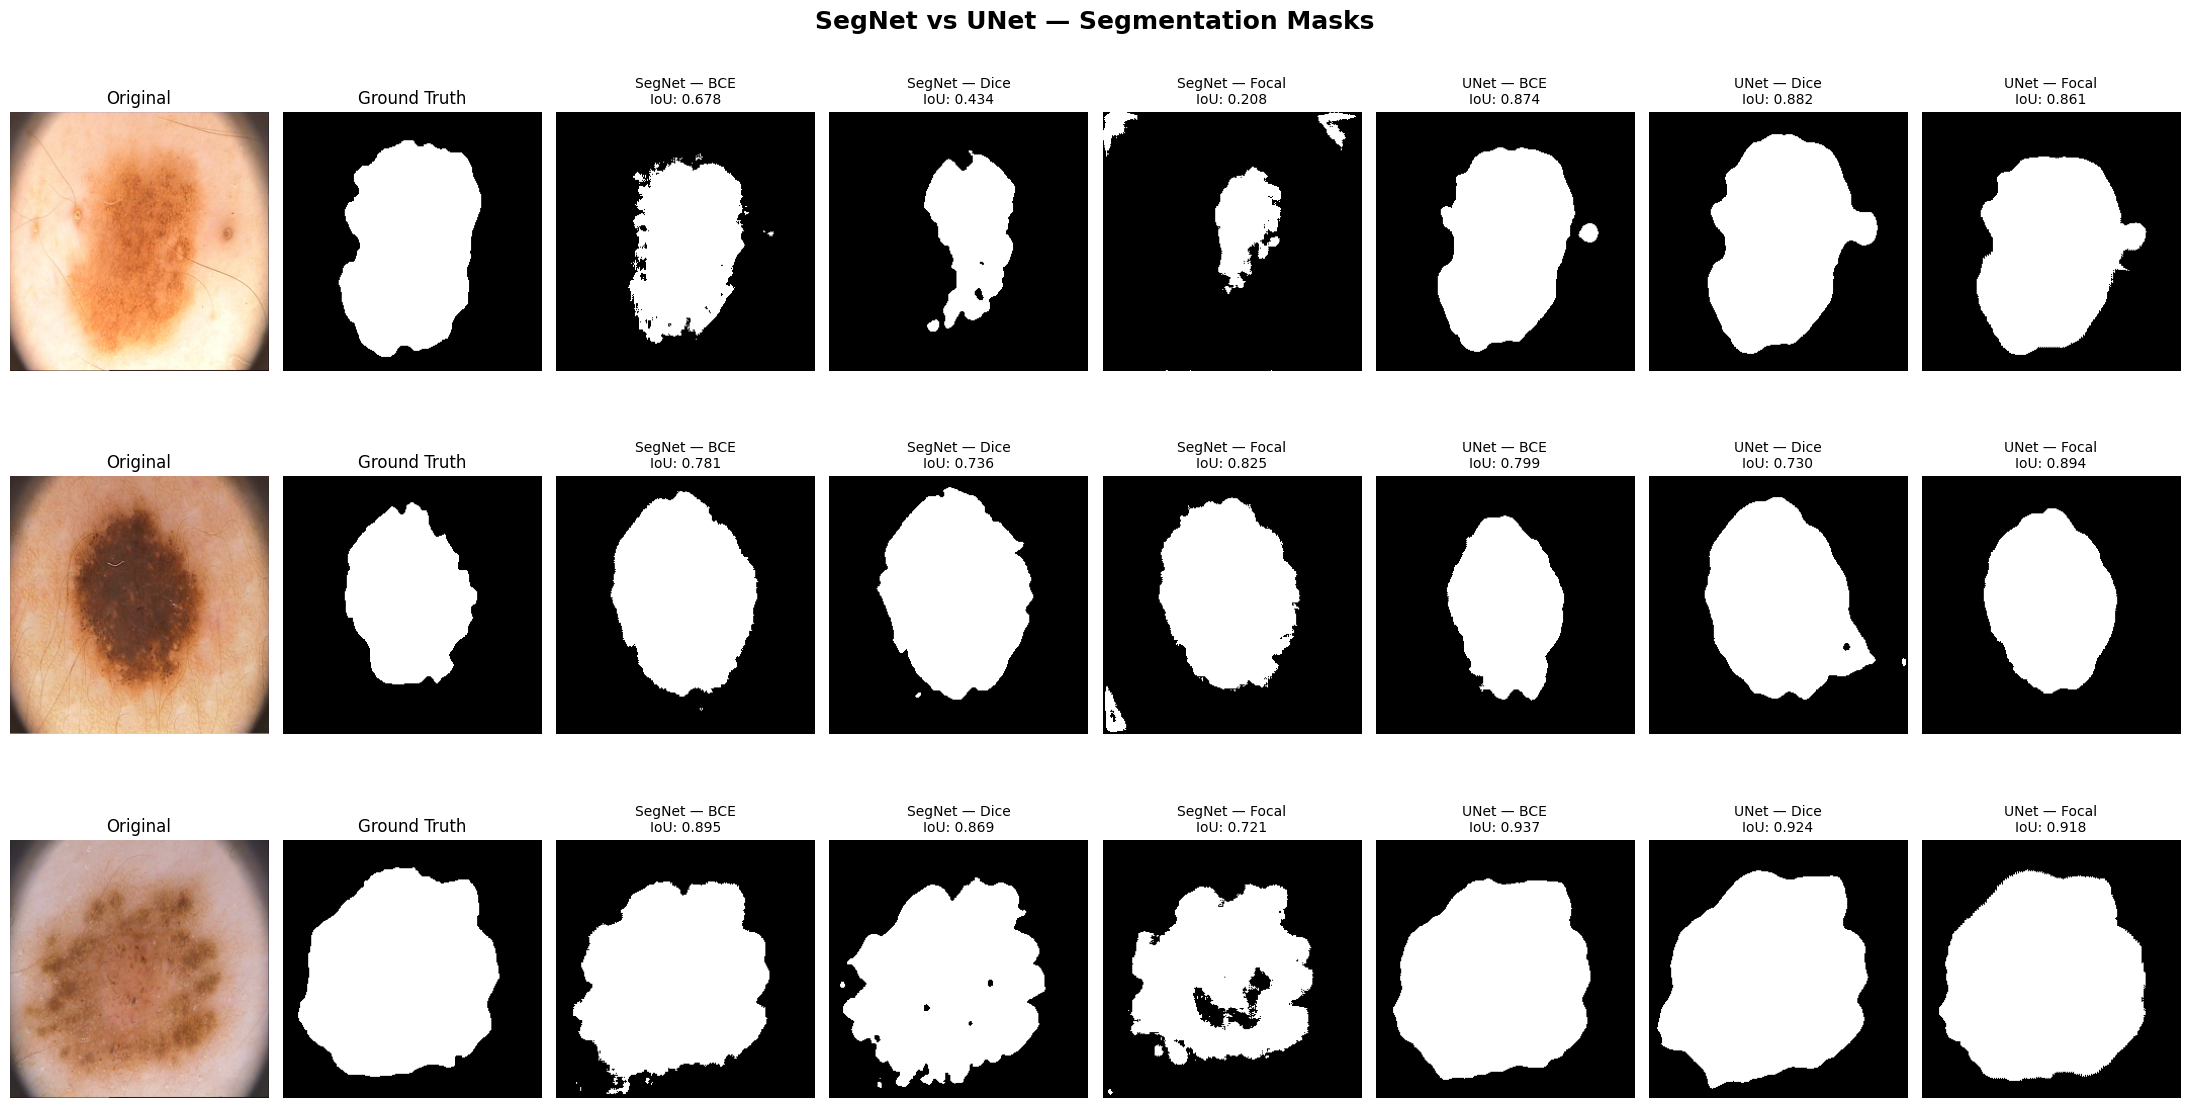

In [65]:
N_SAMPLES = 3
images, masks = next(iter(test_dataloader))

images = images[:N_SAMPLES]
masks = masks[:N_SAMPLES]

models = {
    "SegNet": SegNet,
    "UNet": UNet
}

predictions = {}

for model_name, model_class in models.items():
    for loss_name in ["BCE", "Dice", "Focal"]:
        model = model_class().to(device)

        path = Path("segnet_comparison") / (
            f"{model_name.lower()}_{loss_name.lower()}.pth"
        )

        model.load_state_dict(
            torch.load(path, map_location=device, weights_only=True)
        )
        model.eval()

        with torch.no_grad():
            logits = model(images.to(device).float())
            preds = (torch.sigmoid(logits) >= 0.5)
            predictions[(model_name, loss_name)] = preds.cpu().numpy()

        del model

fig, axes = plt.subplots(N_SAMPLES, 8, figsize=(22, 4 * N_SAMPLES),
                         squeeze=False)

model_keys = list(predictions.keys())

for i in range(N_SAMPLES):
    image = images[i].permute(1, 2, 0).numpy()
    target = masks[i, 0].numpy() > 0.5

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    for j, (model_name, loss_name) in enumerate(model_keys, start=2):
        pred = predictions[(model_name, loss_name)][i, 0]

        intersection = np.logical_and(pred, target).sum()
        union = np.logical_or(pred, target).sum()
        iou = (intersection + 1e-8) / (union + 1e-8)

        axes[i, j].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(
            f"{model_name} — {loss_name}\nIoU: {iou:.3f}",
            fontsize=10
        )

    for ax in axes[i]:
        ax.axis("off")

fig.suptitle("SegNet vs UNet — Segmentation Masks",
             fontsize=18, fontweight="bold")

plt.tight_layout()
plt.savefig("segmentation_masks_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

### 4. Визуальное сравнение результатов SegNet и U-Net

По визуальным результатам **U-Net точнее воспроизводит форму и границы объектов**, формируя более гладкие и целостные маски с меньшим количеством ошибок.

Особенно заметна разница на первом и третьем изображениях, где SegNet допускает пропуски, шумы и ложные срабатывания. U-Net лучше сохраняет структуру объектов, что, вероятно, связано с использованием skip-connections.

**Таким образом, U-Net показывает более качественную сегментацию на рассмотренных изображениях**, что согласуется с полученными значениями IoU.